In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

analysis_df = pd.read_parquet("./weedvlm_scored_responses.parquet")
print(analysis_df.columns)

Index(['id', 'run', 'model', 'question_id', 'status', 'answer', 'reasoning',
       'parsed', 'raw_response', 'warnings', 'error_kind', 'error_message',
       'error_http_status', 'attempts', 'retry_log', 'finish_reason',
       'latency_seconds', 'usage', 'total_tokens', 'cost_usd', 'generation_id',
       'provider', 'image_sha256', 'prompt_version', 'created_at', 'task',
       'position', 'question_type', 'question_text', 'image_id', 'annotated',
       'benchmark_class', 'dataset_name', 'source_image_id', 'annotation_ids',
       'expected_answer', 'choices', 'answer_index', 'ablation_of',
       'true_weed_count', 'true_weed_coverage_fraction', 'target_species',
       'image_width', 'image_height', 'boxes', 'match', 'outcome',
       'localisation_score', 'matched_iou', 'bbox_format', 'pred_boxes',
       'est_count', 'est_coverage_pct', 'count_error', 'abs_count_error',
       'coverage_error_pp', 'abs_coverage_error_pp'],
      dtype='str')


## Weed species Identification

In weed species identification we have two broad results, the multiple choice questions, and the open-ended questions. We want to assess behaviour across these. The broad results are defined as follows:

In [2]:
# MCQ Questions
mcq_scores = (
    analysis_df[
        (analysis_df["task"] == "species_id") & (analysis_df["question_type"] == "species_id_multiple_choice")
        ]
)
print(mcq_scores.groupby("model")["match"].mean().reset_index())
# Open-ended questions
open_scores = (
    analysis_df[
        (analysis_df["task"] == "species_id") & (analysis_df["question_type"] == "species_id_open_ended")
        ]
)
print(open_scores.groupby("model")["match"].mean().reset_index())

                          model     match
0    anthropic/claude-haiku-5.5  0.867672
1  deepseek/deepseek-v4.1-flash     0.895
2         google/gemma-4-31b-it  0.798333
3             openai/gpt-6-luna  0.856667
4            openai/gpt-6.1-sol  0.945312
                          model     match
0    anthropic/claude-haiku-5.5  0.247899
1  deepseek/deepseek-v4.1-flash    0.3125
2         google/gemma-4-31b-it    0.2625
3             openai/gpt-6-luna  0.270833
4            openai/gpt-6.1-sol  0.456693


In [3]:
# Per species analysis, does this affect it much?
per_species_mcq = mcq_scores.groupby("expected_answer")["match"].mean().reset_index()
per_species_oe = open_scores.groupby("expected_answer")["match"].mean().reset_index()

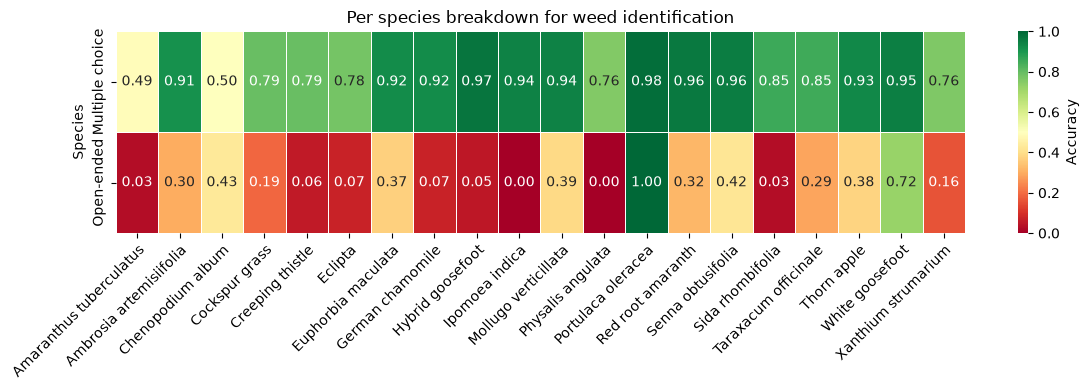

<Figure size 640x480 with 0 Axes>

In [4]:
# Combine into a single dataframe
per_species_df = (
    per_species_mcq.rename(columns={"match": "Multiple choice"})
    .merge(
        per_species_oe.rename(columns={"match": "Open-ended"}),
        on="expected_answer"
    )
    .set_index("expected_answer")
    .astype(float)
)

plt.figure(figsize=(12,4))
ax = sns.heatmap(
    per_species_df.T,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Accuracy"},
)

ax.set_xlabel("")
ax.set_ylabel("Species")
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=45,
    ha="right",
    rotation_mode="anchor"
)
plt.title("Per species breakdown for weed identification")

plt.tight_layout()
plt.show()
plt.savefig("weed_species_id_species_breakdown.png")

In [5]:
# Fine-grained results
fine_grained_results = (
    analysis_df[
        analysis_df["task"] == "fine_grained"
    ].groupby("model")["match"].mean()
)
print(fine_grained_results)
fine_grained_results_ps = (
    analysis_df[
        analysis_df["task"] == "fine_grained"
    ].groupby(["model", "expected_answer"])["match"].mean()
)
print(fine_grained_results_ps)

model
anthropic/claude-haiku-5.5      0.6875
deepseek/deepseek-v4.1-flash    0.7425
google/gemma-4-31b-it           0.7925
openai/gpt-6-luna               0.8025
openai/gpt-6.1-sol                0.75
Name: match, dtype: object
model                         expected_answer  
anthropic/claude-haiku-5.5    Different species     0.62
                              Same species         0.755
deepseek/deepseek-v4.1-flash  Different species     0.64
                              Same species         0.845
google/gemma-4-31b-it         Different species     0.71
                              Same species         0.875
openai/gpt-6-luna             Different species     0.79
                              Same species         0.815
openai/gpt-6.1-sol            Different species      0.7
                              Same species           0.8
Name: match, dtype: object


In [6]:
# Grounded weed VQA
grounded_vqa_responses = analysis_df[
    analysis_df["task"] == "grounded_vqa"
]
grounded_vqa_responses["species"] = grounded_vqa_responses["question_text"].str.extract(
    r"'([^']+)'"
)
grounded_vqa_results = (
    grounded_vqa_responses
    .groupby("model")["match"].mean()
)
print(grounded_vqa_results)
grounded_vqa_ps = (
    grounded_vqa_responses
    .groupby("species")["match"].mean().to_frame().astype(float)
)

model
anthropic/claude-haiku-5.5      0.946667
deepseek/deepseek-v4.1-flash    0.936455
google/gemma-4-31b-it               0.86
openai/gpt-6-luna                   0.91
openai/gpt-6.1-sol              0.966667
Name: match, dtype: object


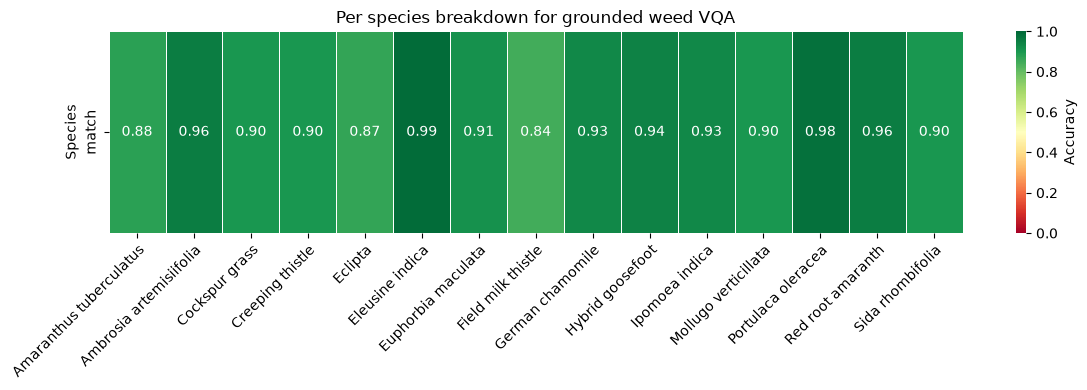

In [7]:
plt.figure(figsize=(12,4))
ax = sns.heatmap(
    grounded_vqa_ps.T,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Accuracy"},
)

ax.set_xlabel("")
ax.set_ylabel("Species")
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=45,
    ha="right",
    rotation_mode="anchor"
)
plt.title("Per species breakdown for grounded weed VQA")

plt.tight_layout()
plt.show()

In [8]:
print(analysis_df[analysis_df["task"] == "grounded_vqa"].question_text.iloc[0])
analysis_df["task"].unique()

Which numbered bounding box contains the weed 'Field milk thistle'?


<ArrowStringArray>
['species_id', 'fine_grained', 'density', 'grounded_vqa', 'localisation']
Length: 5, dtype: str

In [9]:
# Weed localisation
weed_localisation_responses = analysis_df[
    analysis_df["task"] == "localisation"
]
weed_localisation_responses["species"] = weed_localisation_responses["question_text"].str.extract(
    r"instances of (.+?) in this image"
)
weed_localisation_results = (
    weed_localisation_responses
    .groupby("model")[["localisation_score", "matched_iou"]].mean()
)
print(weed_localisation_results)

                              localisation_score  matched_iou
model                                                        
anthropic/claude-haiku-5.5              0.336071     0.689142
deepseek/deepseek-v4.1-flash            0.249398     0.485870
google/gemma-4-31b-it                   0.384303     0.733607
openai/gpt-6-luna                       0.394123     0.623609
openai/gpt-6.1-sol                      0.327589     0.644631


In [10]:
weed_localisatioin_ps = (
    weed_localisation_responses
    .groupby("species")[["localisation_score", "matched_iou"]].mean()
)
print(weed_localisatioin_ps)

                         localisation_score  matched_iou
species                                                 
Amaranthus tuberculatus            0.321571     0.522836
Ambrosia artemisiifolia            0.341516     0.642087
Bassia scoparia                    0.082124     0.399574
Cockspur grass                     0.294906     0.651003
Common corn cockle                 0.518338     0.791345
Copse bindweed                     0.314738     0.744425
Cornflower                         0.654478     0.787097
Creeping thistle                   0.556597     0.755146
Eleusine indica                    0.322477     0.504816
Euphorbia maculata                 0.257051     0.530970
Field bindweed                     0.138560     0.520027
Field milk thistle                 0.152938     0.536566
Geraniums                          0.217101     0.593920
German chamomile                   0.589679     0.796071
Hybrid goosefoot                   0.604391     0.825515
Ipomoea indica                 

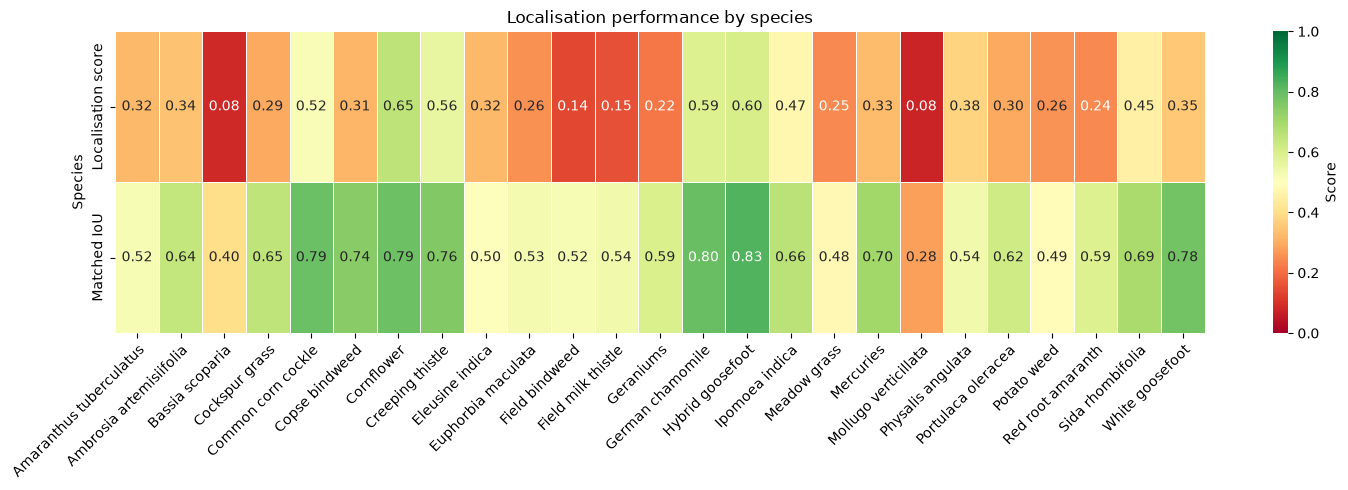

In [11]:
heatmap_data = weed_localisatioin_ps.rename(columns={
    "localisation_score": "Localisation score",
    "matched_iou": "Matched IoU"
})

plt.figure(figsize=(15, 5))

ax = sns.heatmap(
    heatmap_data.T,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Score"},
)

ax.set_xlabel("")
ax.set_ylabel("Species")
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=45,
    ha="right",
    rotation_mode="anchor"
)
plt.title("Localisation performance by species")
plt.tight_layout()
plt.savefig("localisation_species_breakdown.png", dpi=300, bbox_inches="tight")
plt.show()

In [12]:
# Weed density estimation
weed_de_responses = analysis_df[
    analysis_df["task"] == "density"
]

# print(weed_de_responses.columns)

wde_results = (
    weed_de_responses
    .groupby("model")[["match", "abs_count_error", "count_error", "abs_coverage_error_pp", "coverage_error_pp"]].mean()
)

print(wde_results)

                                 match  abs_count_error  count_error  \
model                                                                  
anthropic/claude-haiku-5.5    0.622785         2.159494    -0.124051   
deepseek/deepseek-v4.1-flash     0.445         3.867500    -0.622500   
google/gemma-4-31b-it            0.415         3.952500    -1.592500   
openai/gpt-6-luna                0.415         6.142500     1.622500   
openai/gpt-6.1-sol            0.519608         4.392157     4.029412   

                              abs_coverage_error_pp  coverage_error_pp  
model                                                                   
anthropic/claude-haiku-5.5                 7.468268          -6.820268  
deepseek/deepseek-v4.1-flash               9.891591          -9.462730  
google/gemma-4-31b-it                      6.988139          -6.519405  
openai/gpt-6-luna                         10.135410          -9.767030  
openai/gpt-6.1-sol                         7.953169      

In [13]:
wde_category_results = (
    weed_de_responses
    .groupby("expected_answer")[["match", "abs_count_error", "count_error", "abs_coverage_error_pp", "coverage_error_pp"]].mean()
)
print(wde_category_results)

                    match  abs_count_error  count_error  \
expected_answer                                           
high             0.262222         6.002222    -4.842222   
low              0.922222         3.884444     3.608889   
medium           0.450893         4.138393     0.133929   
none             0.281596         2.286031     2.286031   

                 abs_coverage_error_pp  coverage_error_pp  
expected_answer                                            
high                         16.494008         -16.494008  
low                          10.750362         -10.628772  
medium                        6.043732          -5.977880  
none                          0.911109           0.911109  


In [19]:
print(weed_de_responses["question_text"].to_list()[0])

Select which density category best describes the weeds visible in this image, and estimate how many individual weeds are visible and what percentage of the image area they cover.
